## 1 Preparing image paths 
We are filtering the images so that every image is >=1000 widht and height 


In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("./data/images")
images_dir = data_dir / "small"

metadata = pd.read_csv(data_dir / "metadata" / "images.csv.gz")

filtered_metadata = metadata[(metadata["width"] >= 1000) & (metadata["height"] >= 1000)]

image_paths = [
    str(images_dir / path)
    for path in filtered_metadata["path"]
    if (images_dir / path).is_file()
]

print(f"All metadata records: {len(metadata)}")
print(f"Images meeting size criteria: {len(filtered_metadata)}")
print(f"Existing image files: {len(image_paths)}")

All metadata records: 398212
Images meeting size criteria: 342878
Existing image files: 342878


## Model Selection and some usefull information
As our model we will use clip-ViT-B-32 where ViT stands for the architecture that is being used here which is Vision Transformer. Then B means we are using base version and 32 is just size of the images (in pixels). CLIP is a neural network trained on pairs (image,text). Model provides embeddings for both images and text and represents them in one joined space so then we can search the similar ones. It has 2 encoders one for images and one for texts. Both those encoders returns the 512 lenght vector




## Database Setup 
We will be reusing database from labs named images_homework to avoid name conflict

In [2]:
from sqlalchemy.engine import URL
from sqlalchemy import create_engine

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)

engine = create_engine(db_url)

In [3]:
from typing import List
from pgvector.sqlalchemy import Vector
from sqlalchemy import String
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


class Base(DeclarativeBase):
    __abstract__ = True


class Img(Base):
    __tablename__ = "images_homework"
    __table_args__ = {"extend_existing": True}

    VECTOR_LENGTH: int = 512
    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[List[float]] = mapped_column(Vector(VECTOR_LENGTH))

In [4]:
Base.metadata.create_all(engine)

## 3 Now we move on to the Image vectorization

In [9]:
import joblib
import torch
from sqlalchemy.orm import Session
from PIL import Image
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from itertools import batched

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("clip-ViT-B-32", device=device)


MAX_IMAGES = 1000
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(enginge, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]
            embeddings = model.encode(images, convert_to_tensor=True, device=device)
            imgs = [
                Img(image_path=path, embedding=embedding.tolist())
                for path, embedding in zip(images_paths_batch, embeddings)
            ]

            insert_images(engine, imgs)
            for image in images:
                image.close()
            pbar.update(len(imgs))


vectorize_images(engine, model, image_paths)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

We are adding some more images, we didnt do that before to check how long will 1000 take 

In [10]:
MAX_IMAGES = 4000
vectorize_images(engine, model, image_paths[1000:5000])

  0%|          | 0/4000 [00:00<?, ?it/s]

## Search and result display 

In [12]:
import matplotlib.pyplot as plt
from sqlalchemy import select


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description).tolist()

        query = (
            select(Img.image_path)
            .order_by(Img.embedding.cosine_distance(image_embedding))
            .limit(k)
        )

        with Session(self.engine) as session:
            result = session.execute(query).scalars().all()

        return result

    def display_images(self, images):
        if not images:
            print("no images found")
            return
        k = len(images)
        fig, axes = plt.subplots(1, k, figsize=(15, 5))

        if k == 1:
            axes = [axes]
        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i + 1}")
            img.close()
        plt.show()

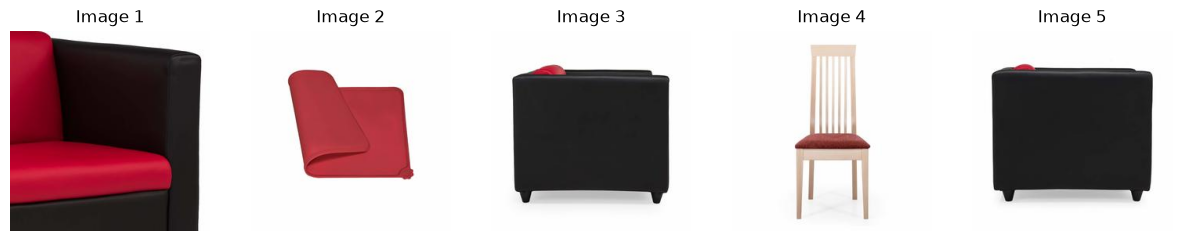

In [13]:
image_search = ImageSearch(engine, model)
image_search("a red chair", k=5)

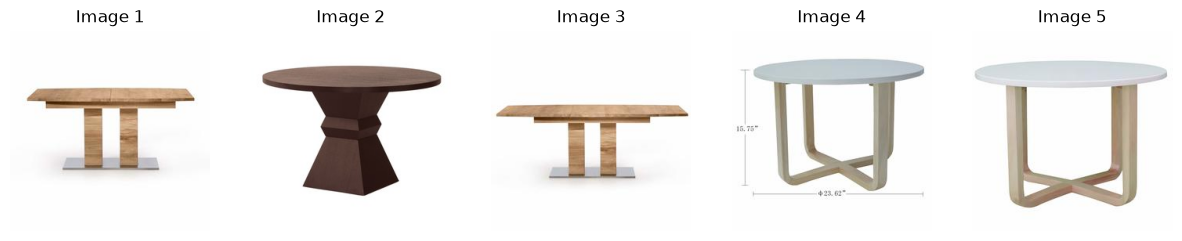

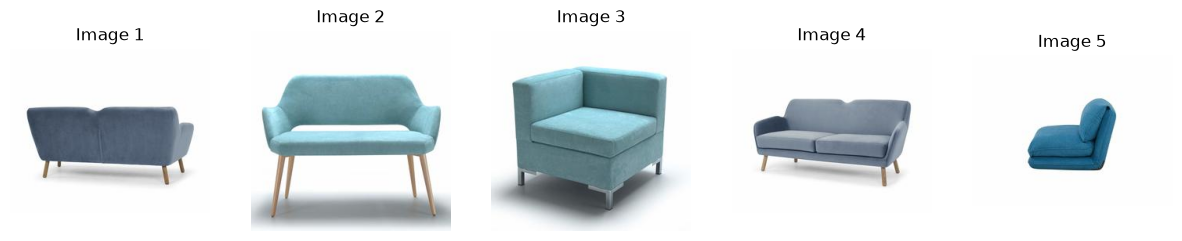

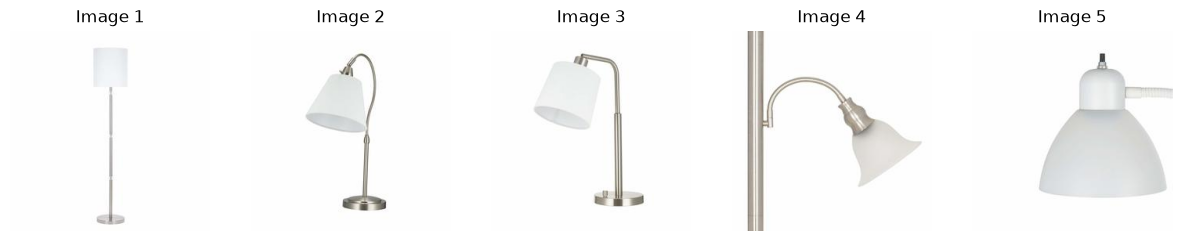

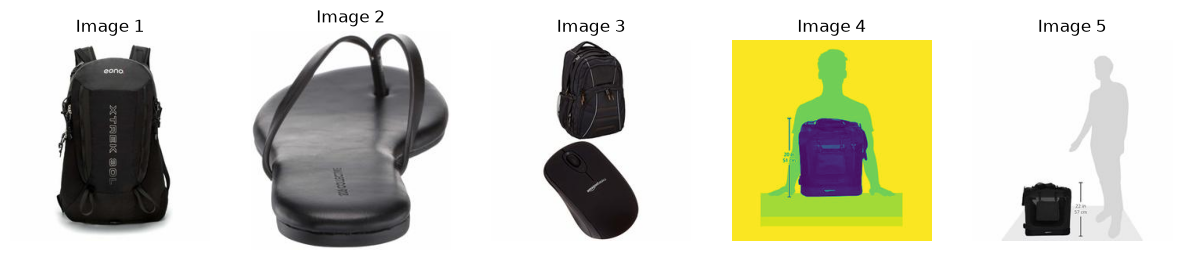

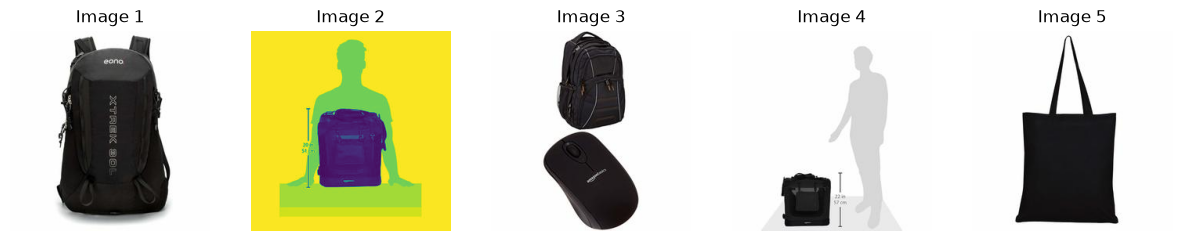

In [15]:
image_search("a wooden dining table", k=5)
image_search("a blue sofa", k=5)
image_search("a white desk lamp", k=5)
image_search("a black leather backpack", k=5)
image_search("a black backpack", k=5)

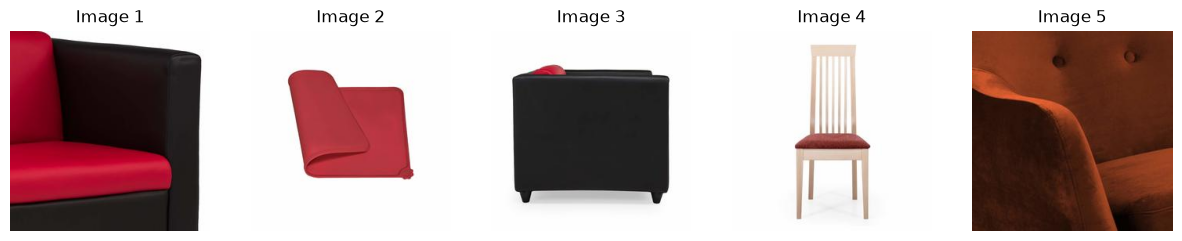

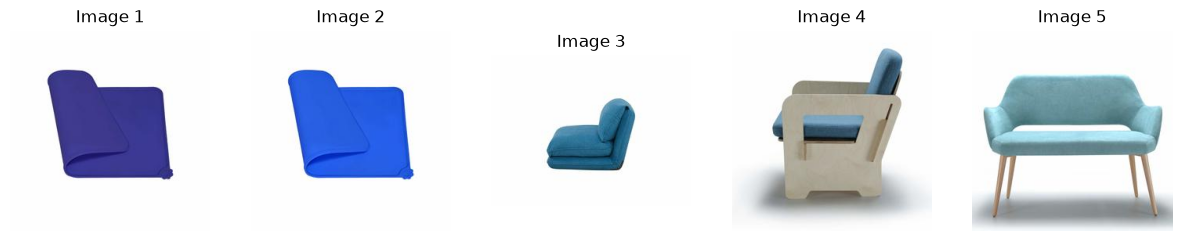

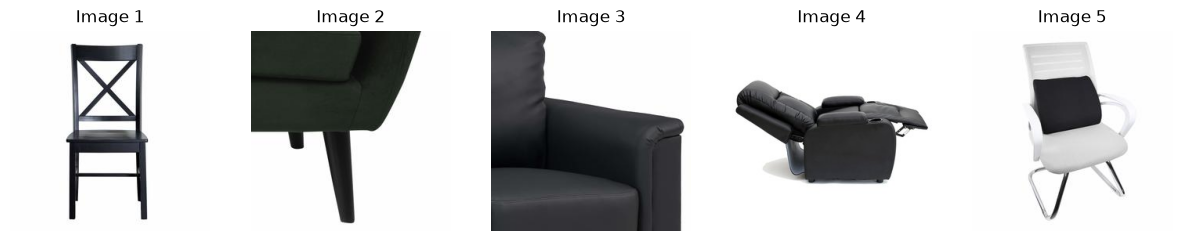

In [16]:
image_search("red chair", k=5)
image_search("blue chair", k=5)
image_search("black chair", k=5)

## Short conclusions

Clip model works as intedted. We can see that by given  text query we get objects described by this text. For "wooden dining table" we got pictures of the table and for "a white desk lamp" pictures of a lamp as intended. We can also see that not only the category is being recognized as the queryes with a different colour of the same item are being processed as one can assume. Matches were not perfectly fine because for example query about "chair" sometimes gave us sofa or some kind of material. This can be a result of limited number of images in the database. Clip also only compares seantic similarity and not each feature separately so sofa will be high in chair ranking because both look similar. Cropped images, close-ups and low image resoluton may also makse some objectives harder to recognize. 